# Long/Short Fallen Angel Raw Signal Backtest

In [1]:
import os
import sys
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt
from   matplotlib.patches import Patch
from   matplotlib.ticker import FuncFormatter

In [2]:
note_path = os.getcwd()
repo_path = os.path.abspath(os.path.join(note_path, ".."))
src_path  = os.path.join(repo_path, "src")
data_path = os.path.join(repo_path, "data")
sig_path  = os.path.join(data_path, "Signal")
fact_path = os.path.join(data_path, "FactorAnalysis")

In [3]:
sys.path.append(src_path)
from FactorAnalysis import FactorAnalysis

In [4]:
fi_ticker_map = {
    'AGG'     : "IG", 
    'HYG'     : "HY", 
    'JNK'     : "HY", 
    'LBUSTRUU': "IG", 
    'LF98TRUU': "HY", 
    'LQD'     : "IG",
    "SPHY"    : "HY", 
    "USHY"    : "HY"}

renamer_ = {
    "lagged" : "Lagged",
    "perfect": "Contemporaneous",
    "no"     : "No",
    "etf"    : "ETF",
    "index"  : "TRUU Index",
    "HY"     : "High Yield",
    "IG"     : "Investment Grade"}

sample_renamer = {
    "in_sample" : "In-Sample",
    "out_sample": "Out-Sample"}

param_namer = {
    "param_val" : "Coef",
    "pvalue"    : r"$p$-value",
    "tvalue"    : r"$t$-value",
    "lag_signal": "Lag",
    "signal"    : "No Lag", }

renamer = {**renamer_, **param_namer, **sample_renamer}

In [5]:
def _get_avg_corr(df_corr: pd.DataFrame) -> pd.DataFrame: 
    mask = np.triu(np.ones(df_corr.shape, dtype=bool), k=1)
    return df_corr.where(mask).stack().mean()

# Making Mean Reversion Backtests

Start by making examining the backtest

In [6]:
rtn_path = os.path.join(sig_path, "MeanReversionRtn.parquet")
yld_path = os.path.join(sig_path, "YieldReversion.parquet")

In [7]:
df_rtn_mr = (pd
    .read_parquet(path = rtn_path, engine = "pyarrow")
    .drop(columns = ["asset"]))

df_yld_mr = (pd
    .read_parquet(path = yld_path, engine = "pyarrow"))

In [8]:
df_rtn_tmp = (df_rtn_mr
    .assign(signal_name = lambda x: x.name)
    [["date", "signal_name", "lag_signal"]])

df_yld_tmp = (df_yld_mr
    .assign(signal_name = lambda x: "ANGL " + x.security + " " + x.variable)
    [["date", "lag_signal", "signal_name"]])

The return spread was calculated using lagged and contemporanous volatility targeted returns, these ultamately had high cross-correlation as seen in the table below. Therefore we'll only use contemporanously targeted. 

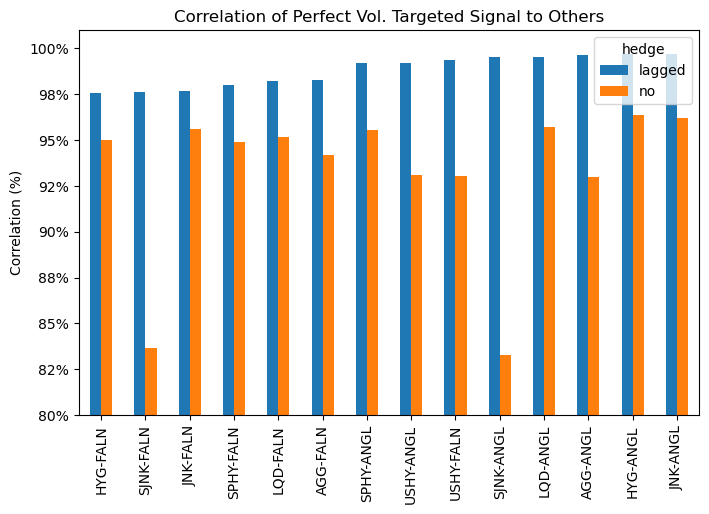

In [9]:
fig, axes = plt.subplots(figsize = (8,5))

df_rtn_wider = (df_rtn_mr
    .assign(spread_name = lambda x: x.fi_ticker + "-" + x.fa_ticker)
    .pivot(index = ["date", "spread_name"], columns = "hedge", values = "lag_signal"))

(df_rtn_wider
    .reset_index()
    .drop(columns = ["date"])
    .dropna()
    .groupby("spread_name")
    .agg("corr")
    .reset_index()
    .loc[lambda x: x.hedge == "perfect"]
    .drop(columns = ["perfect"])
    .set_index("spread_name")
    .drop(columns = ["hedge"])
    .sort_values(["lagged", "no"])
    .plot(
        kind    = "bar",
        ylim    = (0.8, 1.01),
        figsize = (8,5),
        xlabel  = "",
        ylabel  = "Correlation (%)",
        ax      = axes,
        title   = "Correlation of Perfect Vol. Targeted Signal to Others"))

axes.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.show()

In [10]:
df_rtn_keep = (df_rtn_mr
    .assign(signal_name = lambda x: x.fa_ticker + " " + x.fi_ticker + " rtn")
    .loc[lambda x: x.hedge == "perfect"]
    [["date", "signal_name", "lag_signal"]])

In [11]:
df_signal_raw = (pd
    .concat([df_rtn_keep, df_yld_tmp]))

In [12]:
df_signal = (df_signal_raw
    [["signal_name"]]
    .drop_duplicates()
    .assign(
        str_split    = lambda x: x.signal_name.str.split(" "),
        spread_name  = lambda x: x.str_split.str[0] + " " + x.str_split.str[1],
        signal_group = lambda x: x.str_split.str[2])
    .drop(columns = ["str_split"])
    .merge(right = df_signal_raw, how = "inner", on = ["signal_name"]))

In [13]:
df_corr = (df_signal
    .assign(tmp = lambda x: x.spread_name.str.split(" ").str[0])
    .loc[lambda x: x.tmp == "ANGL"]
    .pivot(index = "date", columns = "signal_name", values = "lag_signal")
    .corr())

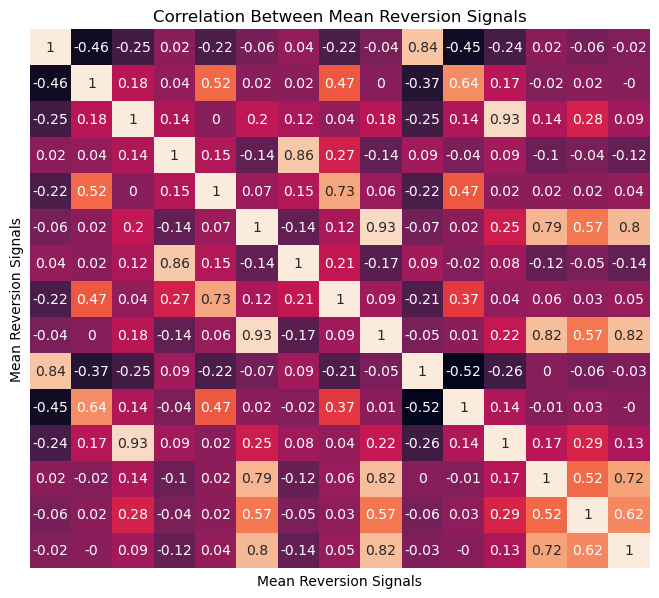

In [14]:
fig, axes = plt.subplots(figsize = (8,7))

sns.heatmap(
    data = df_corr.apply(lambda x: np.round(x,2)),
    ax   = axes,
    annot = True,
    cbar  = False)

axes.set_xticks([])
axes.set_yticks([])
axes.set_xlabel("Mean Reversion Signals")
axes.set_ylabel("Mean Reversion Signals")
axes.set_title("Correlation Between Mean Reversion Signals")
plt.show()

Use volatility targeted returns for L/S spreads, and then apply a volatility target to the signal returns. 

In [15]:
path   = os.path.join(data_path, "PrepData", "Rtn.parquet")
df_rtn = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .loc[lambda x: (x.asset == "etf") & (x.hedge != "no") & (x.fi_ticker != "SJNK")]
    .assign(
        spread_rtn  = lambda x: x.fa_rtn - x.fi_rtn,
        spread_name = lambda x: x.fa_ticker + " " + x.fi_ticker)
    [["date", "hedge", "spread_rtn", "spread_name"]])

In [16]:
def _vol_target(df: pd.DataFrame, target: float = 0.1, lookback: int = 100, threshold: float = 0.1) -> pd.DataFrame:

    lag = df.name[-1]
    if lag == "lagged": shifter = 1
    else              : shifter = 0
    
    df_out = (df
        .sort_values("date")
        .assign(
            vol_rtn = lambda x: x.signal_rtn * (target / (x.signal_rtn.ewm(span = lookback, adjust = False).std().shift(shifter) * np.sqrt(252)))))

    return df_out

df_vol_rtn = (df_signal
    .merge(right = df_rtn, how = "inner", on = ["date", "spread_name"])
    .dropna()
    .assign(
        lag_signal = lambda x: np.where(x.signal_group.str.strip() != "rtn", -x.lag_signal, x.lag_signal),
        signal_rtn = lambda x: -np.sign(x.lag_signal) * x.spread_rtn)
    .groupby(["signal_name", "hedge"])
    .apply(_vol_target)
    .reset_index()
    .drop(columns = ["level_2"])
    .assign(
        fi_ticker = lambda x: x.spread_name.str.split(" ").str[-1].str.strip(),
        fi_group  = lambda x: x.fi_ticker.map(fi_ticker_map)))

In [17]:
color_map = {
    'HY': "skyblue", 
    'IG': "orange"}

legend_handles = [
    Patch(facecolor=color, label=label)
    for label, color in color_map.items()
]

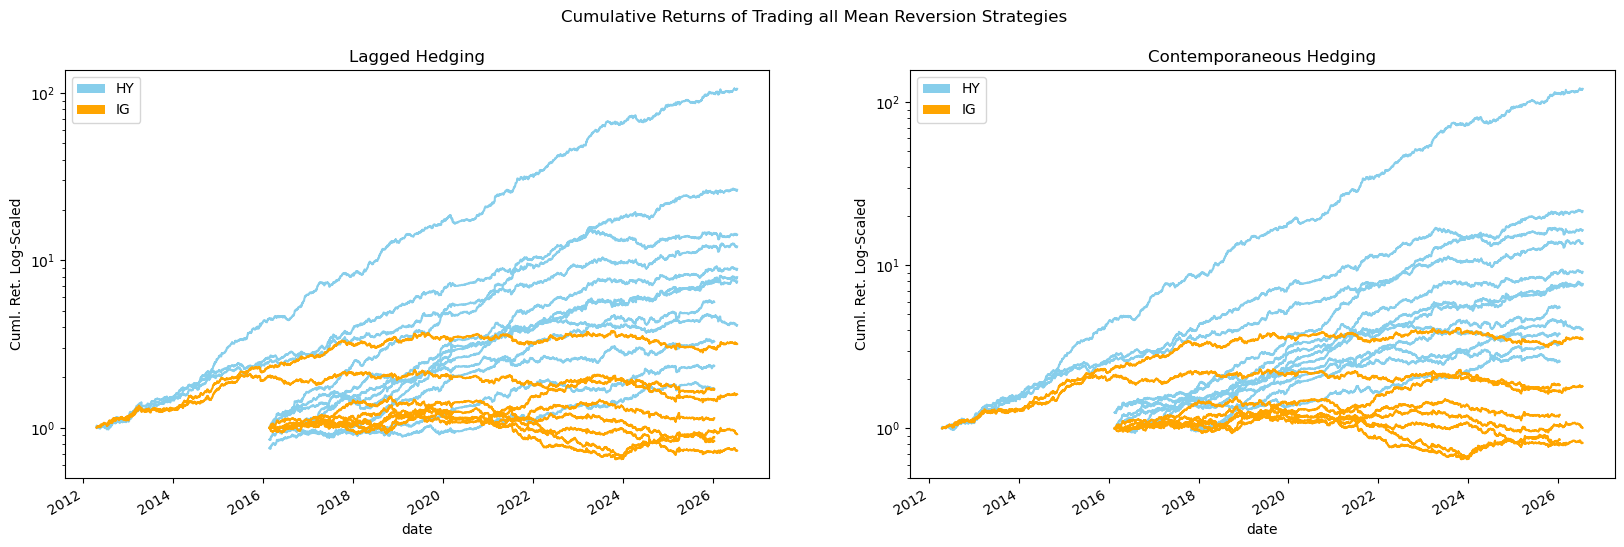

In [18]:
vol_targets = df_vol_rtn.hedge.drop_duplicates().sort_values().to_list()
fi_groups   = df_vol_rtn.fi_group.drop_duplicates().sort_values().to_list()
fig, axes   = plt.subplots(ncols = 2, figsize = (20,6))

for vol_target, ax in zip(vol_targets, axes.flatten()):
    for fi_group in fi_groups: 

        (df_vol_rtn
            .loc[lambda x: (x.hedge == vol_target) & (x.fi_group == fi_group)]
            .pivot(index = "date", columns = "signal_name", values = "vol_rtn")
            .apply(lambda x: np.cumprod(1 + x))
            .plot(logy = True, ax = ax, legend = False, color = color_map[fi_group]))

    ax.legend(handles = legend_handles)
    ax.set_title(renamer[vol_target] + " Hedging")
    ax.set_ylabel("Cuml. Ret. Log-Scaled")

fig.suptitle("Cumulative Returns of Trading all Mean Reversion Strategies")
plt.show()

In [19]:
df_sharpe = (df_vol_rtn
    [["date", "signal_name", "hedge", "vol_rtn"]]
    .drop(columns = ["date"])
    .groupby(["signal_name", "hedge"])
    .agg(lambda x: x.mean() / x.std() * np.sqrt(252))
    .reset_index()
    .pivot(index = "signal_name", columns = "hedge", values = "vol_rtn"))

In [20]:
ols_model = (sm
    .OLS(
        endog = df_sharpe.lagged,
        exog  = sm.add_constant(df_sharpe.perfect))
    .fit())

In [21]:
param_dict = ols_model.params.to_dict()

In [22]:
x = np.linspace(start = df_sharpe.perfect.min(), stop = df_sharpe.perfect.max(), num = 100)
y = (x * param_dict["perfect"] + param_dict["const"])

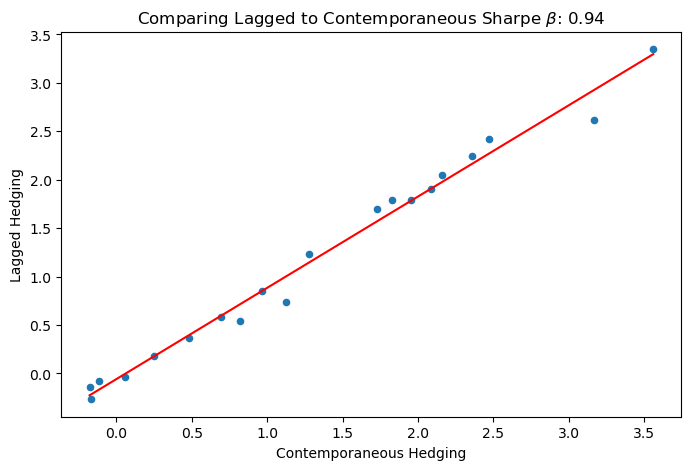

In [23]:
fig, axes = plt.subplots(figsize = (8,5))

(df_sharpe
    .plot(
        kind   = "scatter", 
        x      = "perfect",
        y      = "lagged",
        ax     = axes,
        xlabel = "Contemporaneous Hedging",
        ylabel = "Lagged Hedging",
        title  = r"Comparing Lagged to Contemporaneous Sharpe $\beta$: {}".format(np.round(param_dict["perfect"], 2))))

axes.plot(x, y, color = "red")
plt.show()

In [24]:
(df_sharpe
    .reset_index()
    .assign(
        signal_name = lambda x: x.signal_name.str.replace("GL ", "GL-").str.replace("LN ", "LN-"),
        spread      = lambda x: x.lagged - x.perfect)
    .set_index("signal_name")
    .sort_values("spread"))

hedge,lagged,perfect,spread
signal_name,,,
FALN-SPHY rtn,2.620259,3.167729,-0.547469
ANGL-JNK YAS_MOD_DUR,0.741120,1.127288,-0.386168
ANGL-HYG YAS_MOD_DUR,0.538473,0.817129,-0.278656
ANGL-SPHY rtn,3.347762,3.560632,-0.212870
ANGL-JNK rtn,1.906397,2.087731,-0.181334
ANGL-HYG rtn,1.791627,1.956213,-0.164585
FALN-HYG rtn,2.044965,2.162435,-0.117470
ANGL-LQD rtn,0.854104,0.968000,-0.113895
ANGL-LQD YAS_BOND_YLD,0.583860,0.696739,-0.112879


In [25]:
df_rating_port = (df_vol_rtn
    [["date", "hedge", "fi_group", "vol_rtn"]]
    .groupby(["date", "hedge", "fi_group"])
    .agg("mean")
    .reset_index()
    .assign(
        hedge = lambda x: x.hedge.map(renamer),
        name  = lambda x: x.fi_group + " " + x.hedge))

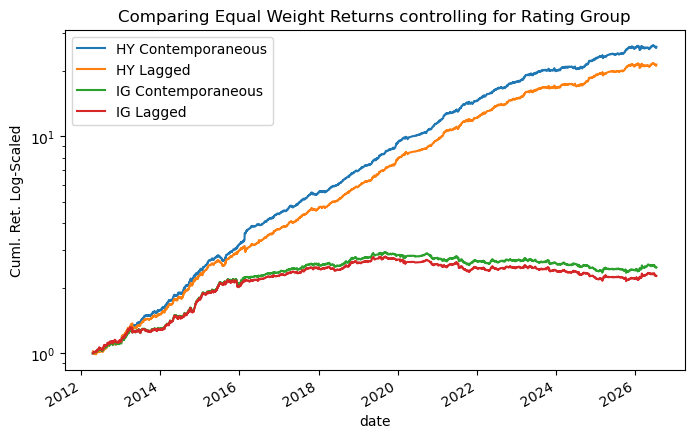

In [26]:
(df_rating_port
    .rename(columns = {"name": ""})
    .pivot(index = "date", columns = "", values = "vol_rtn")
    .apply(lambda x: np.cumprod(1 +x))
    .plot(
        logy    = True,
        ylabel  = "Cuml. Ret. Log-Scaled",
        title   = "Comparing Equal Weight Returns controlling for Rating Group",
        figsize = (8,5)))

plt.show()

In [27]:
(df_rating_port
    .drop(columns = ["name", "date"])
    .groupby(["hedge", "fi_group"])
    .agg(lambda x: x.mean() / x.std() * np.sqrt(252))
    .reset_index()
    .pivot(index = "fi_group", columns = "hedge", values = "vol_rtn"))

hedge,Contemporaneous,Lagged
fi_group,,
HY,3.872665,3.489801
IG,1.039749,0.899056


In [28]:
df_port = (df_vol_rtn
    [["date", "hedge", "vol_rtn"]]
    .groupby(["date", "hedge"])
    .agg("mean")
    .reset_index())

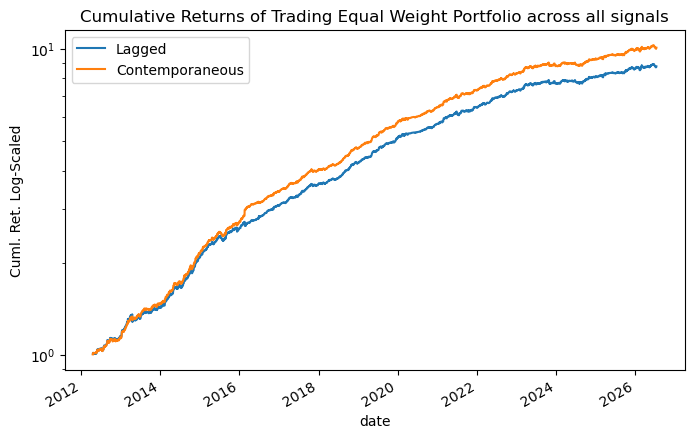

In [29]:
(df_port
    .rename(columns = {"hedge": ""})
    .pivot(index = "date", columns = "", values = "vol_rtn")
    .apply(lambda x: np.cumprod(1 + x))
    .rename(columns = renamer)
    .plot(
        logy    = True,
        figsize = (8,5),
        ylabel  = "Cuml. Ret. Log-Scaled",
        title   = "Cumulative Returns of Trading Equal Weight Portfolio across all signals"))

plt.show()

# Optimized Signal

In [30]:
def _vol_target(df: pd.DataFrame) -> pd.DataFrame:
    
    df_out = (df
        .set_index("date")
        .sort_index()
        .assign(
            signal_rtn = lambda x: np.sign(x.signal_scaler * x.sharpe) * x.spread_rtn,
            weight     = lambda x: (0.1 / (x.signal_rtn.ewm(span = 100, adjust = False).std() * np.sqrt(252))),
            lag_weight = lambda x: x.weight.shift()))

    return df_out

path = os.path.join(data_path, "OptimizedSignal", "MeanReversionOptSignal.parquet")
df_opt_signal = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .assign(tmp_name = lambda x: x.signal_name + " " + x.sample_group)
    .drop(columns = "hedge")
    .groupby("tmp_name")
    .apply(_vol_target)
    .reset_index())

In [31]:
df_opt_prep = (df_opt_signal
    [["tmp_name", "date", "sample_group", "signal_rtn", "weight", "lag_weight"]]
    .rename(columns = {"weight": "perfect", "lag_weight": "lagged"})
    .melt(id_vars = ["date", "tmp_name", "sample_group", "signal_rtn"])
    .assign(
        name         = lambda x: x.variable.map(renamer) + " " + x.sample_group.map(renamer),
        fi_ticker    = lambda x: x.tmp_name.str.split(" ").str[1].map(fi_ticker_map),
        sig_type     = lambda x: np.where(x.tmp_name.str.split(" ").str[2] == "rtn", "Returns", "Yield"),
        color_name   = lambda x: x.fi_ticker + " " + x.sig_type, 
        weighted_rtn = lambda x: np.sign(x.value) * x.signal_rtn)
    .dropna())

In [32]:
color_map = {
    'HY Returns': "tab:blue", 
    'HY Yield'  : "tab:red", 
    'IG Returns': "tab:green", 
    'IG Yield'  : "tab:orange"}

legend_handles = [
    Patch(facecolor=color, label=label)
    for label, color in color_map.items()
]

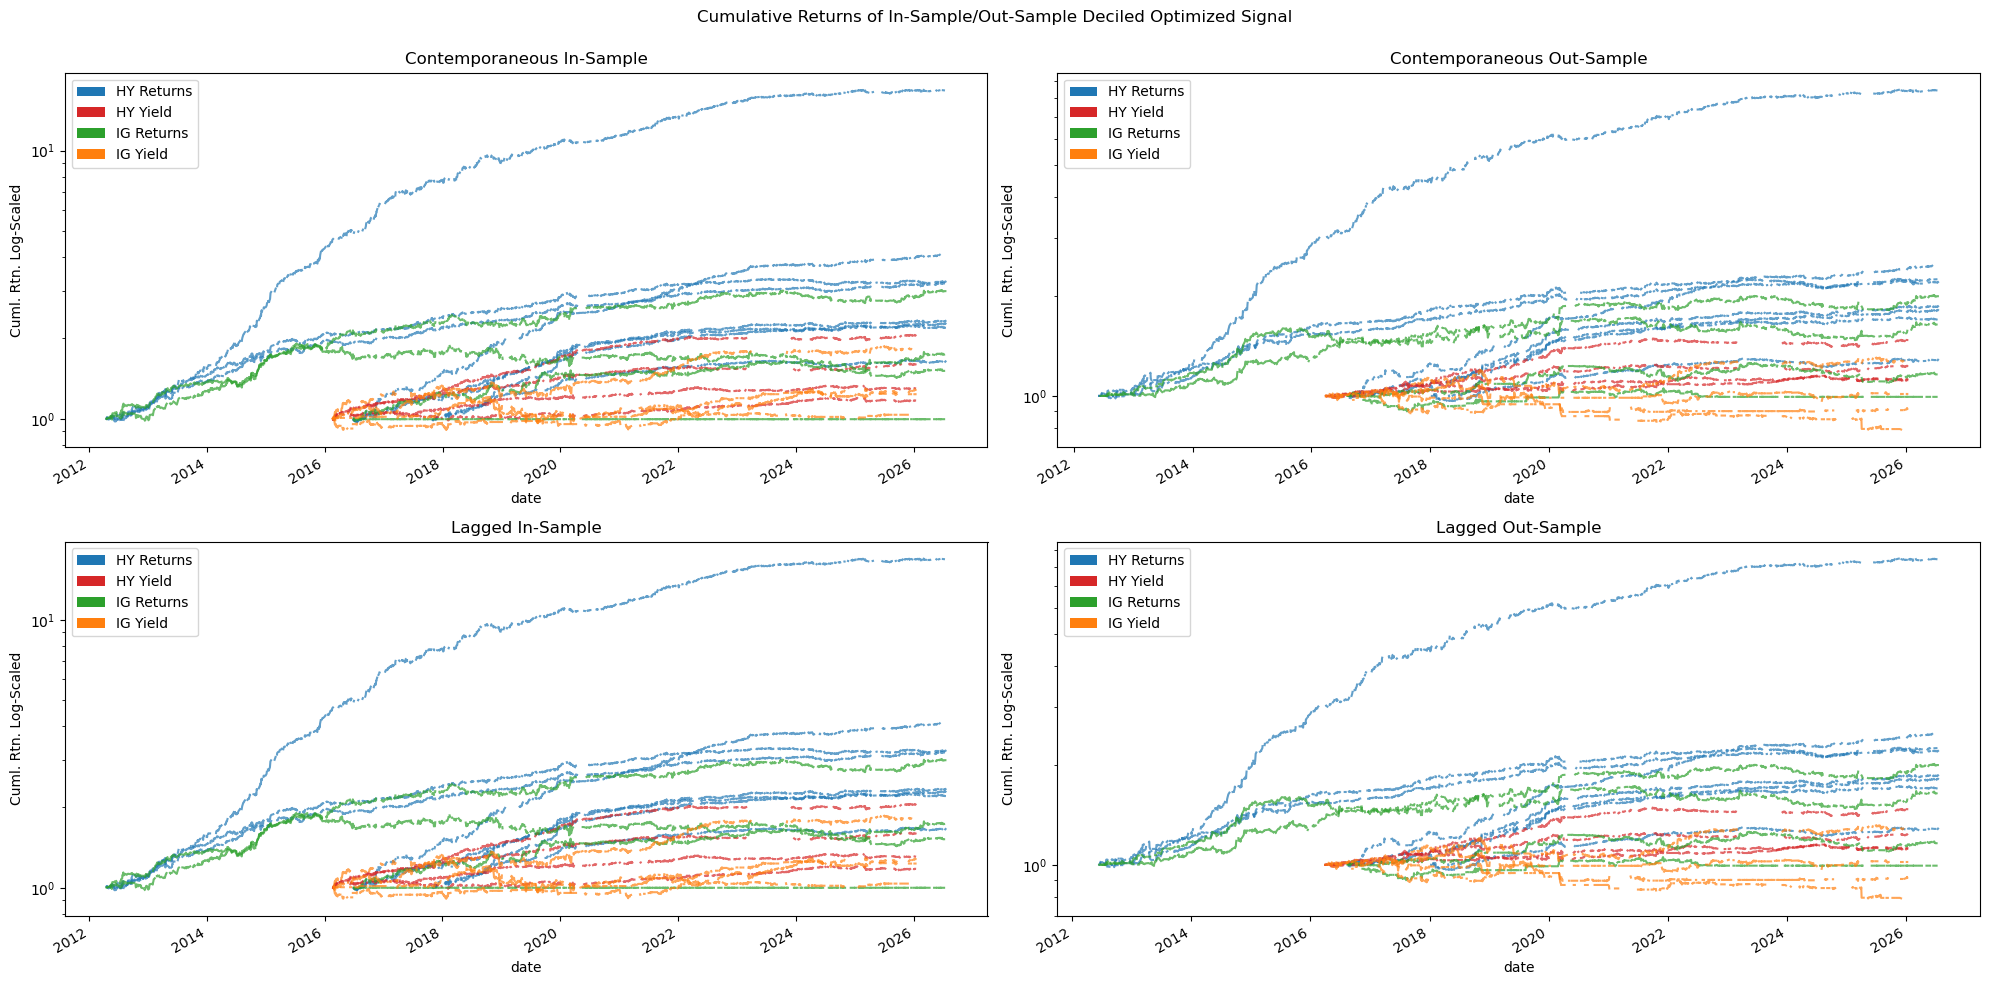

In [33]:
names = df_opt_prep.name.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = 2, nrows = 2, figsize = (20,10))

for name, ax in zip(names, axes.flatten()):
    for key in color_map.keys():

        (df_opt_prep
            .loc[lambda x: (x.name == name) & (x.color_name == key)]
            .pivot(index = "date", columns = "tmp_name", values = "weighted_rtn")
            .apply(lambda x: np.cumprod(1 + x))
            .plot(
                ax = ax,
                legend = False,
                color  = color_map[key],
                logy   = True,
                alpha  = 0.7))

    ax.legend(handles = legend_handles)
    ax.set_ylabel("Cuml. Rtn. Log-Scaled")
    ax.set_title(name)

fig.suptitle("Cumulative Returns of In-Sample/Out-Sample Deciled Optimized Signal\n")
plt.tight_layout()

In [34]:
df_rating_port = (df_opt_prep
    [["date", "name", "color_name", "weighted_rtn"]]
    .groupby(["date", "name", "color_name"])
    .agg("mean")
    .reset_index())

In [35]:
df_rating_port

,date,name,color_name,weighted_rtn
0,2012-04-18,Contemporaneous In-Sample,HY Returns,0.001853
1,2012-04-18,Contemporaneous In-Sample,IG Returns,0.004007
2,2012-04-19,Contemporaneous In-Sample,HY Returns,0.008958
3,2012-04-19,Lagged In-Sample,HY Returns,0.008958
4,2012-04-20,Contemporaneous In-Sample,HY Returns,0.004802
...,...,...,...,...
30170,2026-07-16,Lagged Out-Sample,IG Returns,-0.000011
30171,2026-07-17,Contemporaneous In-Sample,HY Returns,0.002607
30172,2026-07-17,Contemporaneous Out-Sample,HY Returns,0.002591
30173,2026-07-17,Lagged In-Sample,HY Returns,0.002607


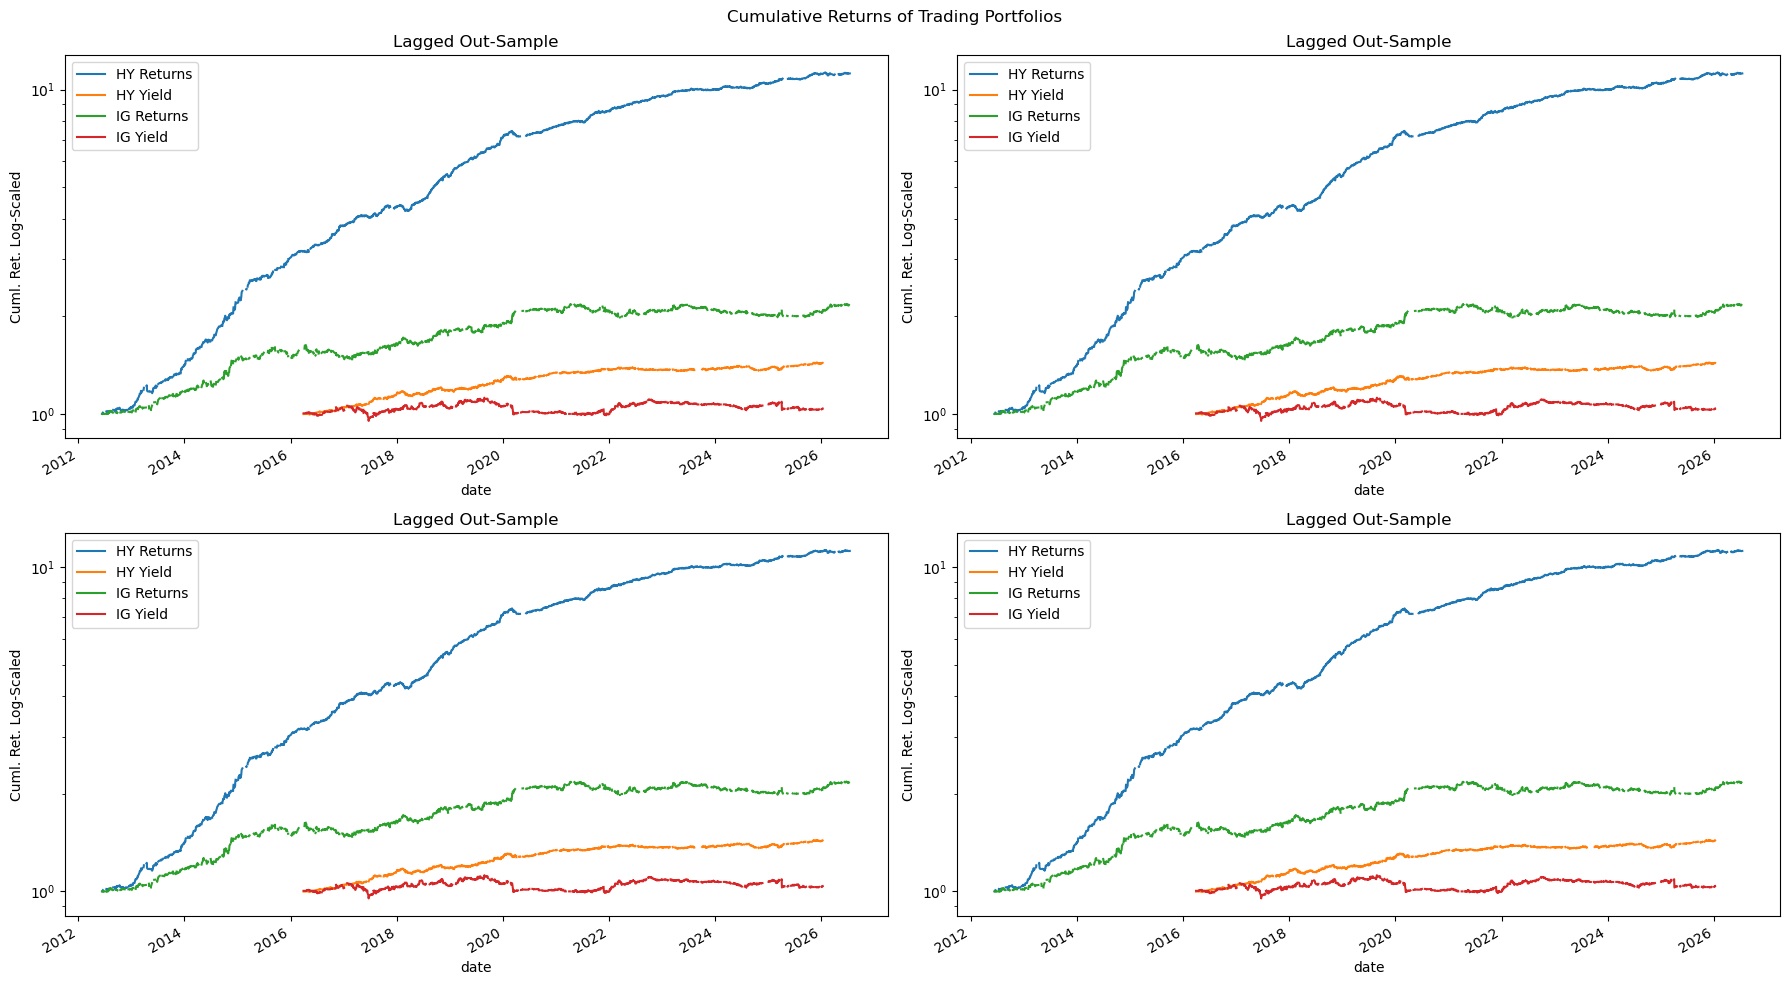

In [36]:
names     = df_rating_port.name.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = len(names) // 2, nrows = len(names) // 2, figsize = (18,10))

for names, ax in zip(names, axes.flatten()):

    (df_rating_port
        .loc[lambda x: x.name == name]
        .rename(columns = {"color_name": ""})
        .pivot(index = "date", columns = "", values = "weighted_rtn")
        .apply(lambda x: np.cumprod(1 + x))
        .plot(
            logy   = True, 
            ax     = ax,
            ylabel = "Cuml. Ret. Log-Scaled",
            title  = name))

fig.suptitle("Cumulative Returns of Trading Portfolios")
plt.tight_layout()

In [37]:
(df_rating_port
    .drop(columns = ["date"])
    .groupby(["name", "color_name"])
    .agg(lambda x: x.mean() / x.std() * np.sqrt(252))
    .reset_index()
    .pivot(index = "name", columns = "color_name", values = "weighted_rtn"))

color_name,HY Returns,HY Yield,IG Returns,IG Yield
name,,,,
Contemporaneous In-Sample,4.573621,2.133963,1.630564,0.761039
Contemporaneous Out-Sample,4.475331,1.724322,1.436102,0.115623
Lagged In-Sample,4.581703,2.128794,1.631593,0.754889
Lagged Out-Sample,4.482420,1.730122,1.437767,0.133062
